# 🚀 PropulPy (Notebook Principal): De un `Rocket` y `Environment` en RocketPy al Diseño Automático del Motor KNSB para Alcanzar Exactamente 1 km de Apogeo

### ¿Qué problema resuelve PropulPy y qué automatiza exactamente?

En **RocketPy**, tú defines tu **cohete (`Rocket`)** —con su masa estructural, ojiva (`nosecone`), aletas (`fins`) y botones de riel (`rail_buttons`)— y el **entorno de lanzamiento (`Environment`)** con su altitud, presión barométrica local $P_a(z)$ y gravedad $g(z)$.

Sin embargo, para que ese cohete vuele en `rocketpy.Flight`, necesitas un **`SolidMotor`**. Y ahí surge la pregunta fundamental de ingeniería inversa que **PropulPy** resuelve de forma automática:

> **«Ya tengo mi objeto `Rocket` (con su ojiva, aletas y masa) y mi objeto `Environment` en RocketPy. Quiero llegar exactamente a $1\text{ km}$ ($1000\text{ m}$) de apogeo usando propelente sólido `KNSB`. ¿Qué motor exacto (longitud de granos, diámetro de garganta $D_t$, diámetro de salida de tobera $D_e$, conos de tobera y curva de empuje) necesito fabricar?»**

En este notebook principal veremos de forma visual e intuitiva:
1. **Punto de partida**: Creamos el objeto `Environment` y el objeto `Rocket` de `RocketPy` con su `nosecone`, `fins` y `rail_buttons`.
2. **Automatización del diseño inverso (`design_motor_for_rocket_apogee`)**: Cómo `PropulPy` acopla en un lazo cerrado la balística interna (`KNSB` + `BATES`), el dimensionamiento isentrópico de la tobera (`dimension_nozzle`), la conversión a `rocketpy.SolidMotor` y la simulación 6-DOF en `rocketpy.Flight` hasta clavar **$1000.0\text{ m}$ ($1\text{ km}$) de apogeo**.
3. **Radiografía visual de `dimension_nozzle()`**: Cómo, dada la garganta y la presión de salida requerida, `PropulPy` obtiene la geometría exacta de la tobera y el perfil supersónico del gas.
4. **Verificación explícita en `rocketpy.Flight`**: Montamos el `SolidMotor` resultante en el `Rocket`, corremos `Flight` y comprobamos que alcanza exactamente **$1\text{ km}$ de apogeo**.

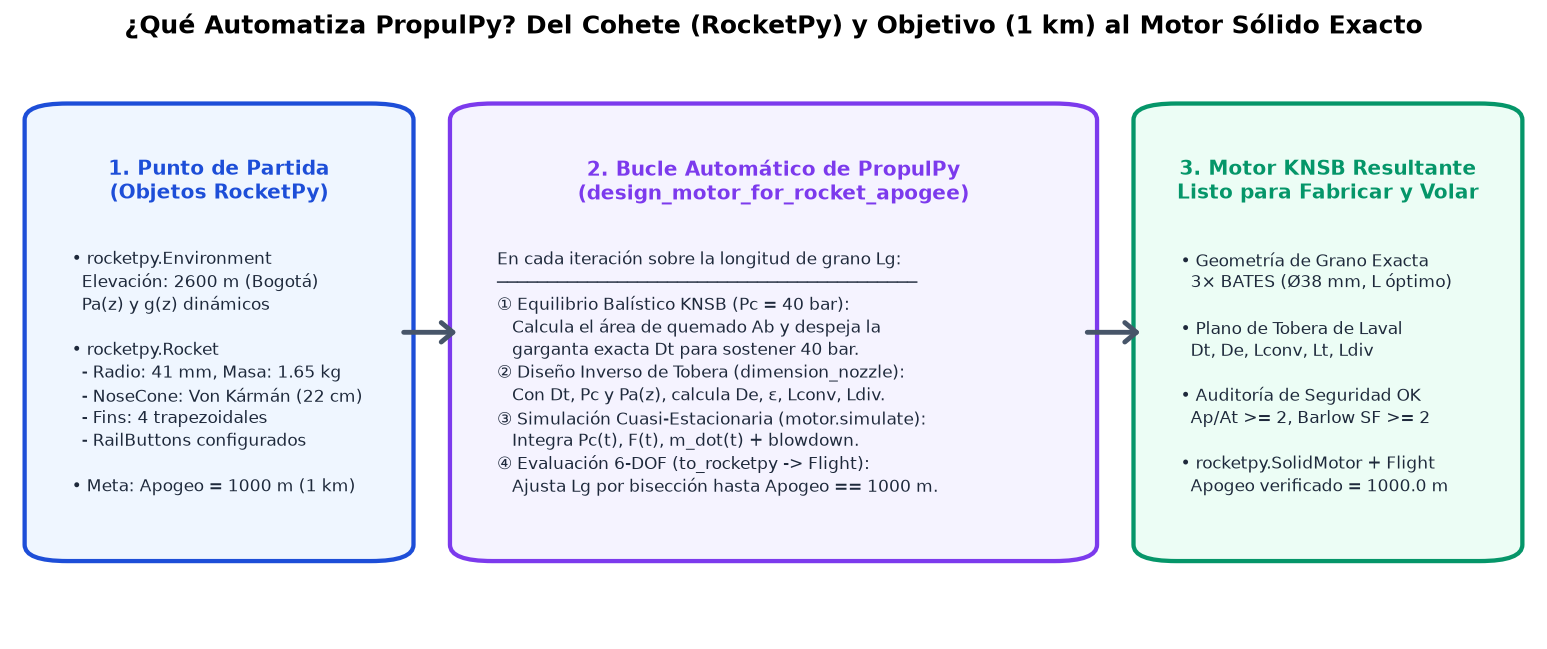

In [1]:
from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
from rocketpy import Environment, Flight, Rocket
from scipy.ndimage import distance_transform_edt

from propulpy import (
    BATES,
    KNSB,
    AmbientConditions,
    EndBurner,
    Finocyl,
    Star,
    constants_from_environment,
    design_motor_for_rocket_apogee,
    dimension_nozzle,
)
from propulpy.analysis.checks import print_check_report

fig_dir = Path("examples/figures") if Path("examples").exists() else Path("figures")
fig_dir.mkdir(parents=True, exist_ok=True)


def plot_propulpy_inverse_loop_diagram(save_path: Path | None = None):
    """Ilustra qué automatiza PropulPy partiendo de un Rocket + Environment hacia 1 km de apogeo."""
    fig, ax = plt.subplots(figsize=(14, 5.4), dpi=140)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.axis("off")
    ax.set_title(
        "¿Qué Automatiza PropulPy? Del Cohete (RocketPy) y Objetivo (1 km) al Motor Sólido Exacto",
        fontsize=13,
        fontweight="bold",
        pad=10,
    )

    blocks = [
        (
            2,
            14,
            23,
            76,
            "#eff6ff",
            "#1d4ed8",
            "1. Punto de Partida\n(Objetos RocketPy)",
            "• rocketpy.Environment\n  Elevación: 2600 m (Bogotá)\n  Pa(z) y g(z) dinámicos\n\n• rocketpy.Rocket\n  - Radio: 41 mm, Masa: 1.65 kg\n  - NoseCone: Von Kármán (22 cm)\n  - Fins: 4 trapezoidales\n  - RailButtons configurados\n\n• Meta: Apogeo = 1000 m (1 km)",
        ),
        (
            30,
            14,
            40,
            76,
            "#f5f3ff",
            "#7c3aed",
            "2. Bucle Automático de PropulPy\n(design_motor_for_rocket_apogee)",
            "En cada iteración sobre la longitud de grano Lg:\n──────────────────────────────────────────\n① Equilibrio Balístico KNSB (Pc = 40 bar):\n   Calcula el área de quemado Ab y despeja la\n   garganta exacta Dt para sostener 40 bar.\n② Diseño Inverso de Tobera (dimension_nozzle):\n   Con Dt, Pc y Pa(z), calcula De, ε, Lconv, Ldiv.\n③ Simulación Cuasi-Estacionaria (motor.simulate):\n   Integra Pc(t), F(t), m_dot(t) + blowdown.\n④ Evaluación 6-DOF (to_rocketpy -> Flight):\n   Ajusta Lg por bisección hasta Apogeo == 1000 m.",
        ),
        (
            75,
            14,
            23,
            76,
            "#ecfdf5",
            "#059669",
            "3. Motor KNSB Resultante\nListo para Fabricar y Volar",
            "• Geometría de Grano Exacta\n  3× BATES (Ø38 mm, L óptimo)\n\n• Plano de Tobera de Laval\n  Dt, De, Lconv, Lt, Ldiv\n\n• Auditoría de Seguridad OK\n  Ap/At >= 2, Barlow SF >= 2\n\n• rocketpy.SolidMotor + Flight\n  Apogeo verificado = 1000.0 m",
        ),
    ]

    for x, y, w, h, fc, ec, title, body in blocks:
        patch = mpatches.FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=1.3,rounding_size=2.8",
            fc=fc,
            ec=ec,
            lw=2.2,
        )
        ax.add_patch(patch)
        ax.text(
            x + w / 2,
            y + h - 8,
            title,
            ha="center",
            va="top",
            fontsize=10.2,
            fontweight="bold",
            color=ec,
        )
        ax.text(
            x + 1.8,
            y + (h - 14) / 2,
            body,
            ha="left",
            va="center",
            fontsize=8.6,
            color="#1e293b",
            linespacing=1.36,
        )

    arrow_kw = {
        "arrowstyle": "->,head_width=0.5,head_length=0.6",
        "lw": 2.5,
        "color": "#475569",
    }
    ax.annotate("", xy=(29.4, 52), xytext=(25.4, 52), arrowprops=arrow_kw)
    ax.annotate("", xy=(74.4, 52), xytext=(70.4, 52), arrowprops=arrow_kw)

    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_propulpy_inverse_loop_diagram(fig_dir / "01_propulpy_architecture.png")

---
## 1. Punto de Partida: Definir el `Environment` y el `Rocket` en RocketPy

Comenzamos exactamente como en cualquier proyecto de `RocketPy`:
1. Instanciamos `env = Environment(...)` para nuestro sitio de lanzamiento (Bogotá a $2600\text{ m}$ MSNM) y extraemos sus propiedades dinámicas ($P_a(z)$, $g(z)$, $T_a(z)$, $\rho_a(z)$, $a(z)$) mediante `constants_from_environment(env)` y `AmbientConditions(env)`.
2. Instanciamos nuestro objeto **`rocket = Rocket(...)`** (sin motor aún), y le añadimos su **ojiva (`add_nose`)**, sus **4 aletas trapezoidales (`add_trapezoidal_fins`)** y sus **botones de riel (`set_rail_buttons`)**.

In [2]:
# 1. Crear el objeto Environment de RocketPy (Bogotá, 2600 m MSNM)
env = Environment(latitude=4.6097, longitude=-74.0817, elevation=2600.0)
env.set_atmospheric_model(type="standard_atmosphere")

# PropulPy extrae dinámicamente presión, gravedad, temperatura y velocidad del sonido de env
env_consts = constants_from_environment(env)
amb = AmbientConditions(env)

print("=== PROPIEDADES EXTRAÍDAS DINÁMICAMENTE DE rocketpy.Environment ===")
print(f"  * Elevación de rampa (z)     : {env_consts.altitude_asl:.1f} m MSNM")
print(
    f"  * Presión barométrica Pa(z)  : {env_consts.pressure / 1e5:.3f} bar ({env_consts.pressure:.0f} Pa)"
)
print(f"  * Gravedad local g(z)        : {env_consts.gravity:.5f} m/s^2")
print(f"  * Temperatura local Ta(z)    : {env_consts.temperature:.2f} K")
print(f"  * Densidad del aire rho(z)   : {env_consts.density:.4f} kg/m^3")
print(f"  * Velocidad del sonido a(z)  : {env_consts.speed_of_sound:.2f} m/s\n")

# 2. Crear el objeto Rocket de RocketPy con su NoseCone, Fins y RailButtons (aún sin motor)
rocket = Rocket(
    radius=0.041,  # Fuselaje de 82 mm de diámetro exterior (radio = 41 mm)
    mass=1.650,  # Masa del cohete sin motor [kg]
    inertia=(0.18, 0.18, 0.002),
    power_off_drag=0.45,
    power_on_drag=0.45,
    center_of_mass_without_motor=0.0,
    coordinate_system_orientation="tail_to_nose",
)

# Añadir Ojiva (NoseCone Von Kármán), 4 Aletas Trapezoidales y Botones de Guía
rocket.add_nose(length=0.22, kind="von karman", position=0.55)
rocket.add_trapezoidal_fins(
    n=4,
    root_chord=0.12,
    tip_chord=0.05,
    span=0.09,
    position=-0.95,
)
rocket.set_rail_buttons(upper_button_position=0.10, lower_button_position=-0.75)

print(
    "Objeto rocketpy.Rocket configurado exitosamente con NoseCone, 4 Aletas y RailButtons."
)

=== PROPIEDADES EXTRAÍDAS DINÁMICAMENTE DE rocketpy.Environment ===
  * Elevación de rampa (z)     : 2600.0 m MSNM
  * Presión barométrica Pa(z)  : 0.738 bar (73758 Pa)
  * Gravedad local g(z)        : 9.77264 m/s^2
  * Temperatura local Ta(z)    : 271.28 K
  * Densidad del aire rho(z)   : 0.9472 kg/m^3
  * Velocidad del sonido a(z)  : 329.62 m/s

Objeto rocketpy.Rocket configurado exitosamente con NoseCone, 4 Aletas y RailButtons.


---
## 2. Diseño Inverso Automático del Motor KNSB para Llegar Exactamente a 1 km de Apogeo

Ahora le pasamos nuestro objeto `rocket` y nuestro objeto `env` a **`design_motor_for_rocket_apogee()`** con el objetivo `target_apogee=1000.0` ($1\text{ km}$ sobre el suelo) y propelente `KNSB(cstar_efficiency=0.95)`.

### ¿Qué hace `design_motor_for_rocket_apogee` automáticamente en cada iteración?
1. Propone una longitud de segmento de grano `BATES` ($L_g$) para los $3$ granos de $\varnothing 38\text{ mm}$ ($d_0 = 12.5\text{ mm}$).
2. Evalúa el área de quemado $A_b$ y calcula el **diámetro exacto de garganta $D_t$** necesario para que el motor opere a la presión de diseño de cámara ($P_c = 40\text{ bar}$).
3. Invoca **`dimension_nozzle()`** usando la presión atmosférica de `env` ($0.738\text{ bar}$) para dimensionar el diámetro de salida $D_e$ y las longitudes de cono $L_{\text{conv}}, L_t, L_{\text{div}}$.
4. Ejecuta la simulación cuasi-estacionaria de balística interna (`motor.simulate(ambient_pressure=env)`).
5. Convierte el motor en un `rocketpy.SolidMotor` (`results.to_rocketpy()`), lo monta en una copia del `rocket` y ejecuta `rocketpy.Flight` hasta encontrar la longitud de grano que clava **$1000.0\text{ m}$ ($1\text{ km}$) de apogeo**:

In [3]:
# Propelente sólido KNSB 65/35
prop = KNSB(cstar_efficiency=0.95)

# Ejecutar el diseño inverso automático para alcanzar exactamente 1000 m (1 km) de apogeo AGL
design = design_motor_for_rocket_apogee(
    rocket=rocket,
    environment=env,
    target_apogee=1000.0,  # ¡Objetivo: 1 km exacto de apogeo AGL!
    propellant=prop,
    num_grains=3,
    grain_outer_diameter=38.0e-3,
    core_diameter=12.5e-3,
    design_chamber_pressure=40.0e5,  # Presión nominal de cámara = 40 bar
    apogee_tolerance_pct=0.25,  # Tolerancia estricta: ±0.25% (±2.5 m)
)

print("==========================================================================")
print("   MOTOR KNSB DISEÑADO AUTOMÁTICAMENTE POR PROPULPY PARA 1 KM DE APOGEO   ")
print("==========================================================================")
print(f"  * Apogeo Objetivo              : {design.target_apogee_m:.1f} m (1.000 km)")
print(
    f"  * Apogeo Alcanzado (Flight)    : {design.simulated_apogee_m:.2f} m ({design.apogee_error_pct:+.3f} %)"
)
print(f"  * Evaluaciones RocketPy Flight : {design.iterations}")
print("--------------------------------------------------------------------------")
print(
    "  * Configuración de Granos      : 3 × BATES (Øext = 38.0 mm, Ønúcleo = 12.5 mm)"
)
print(
    f"  * Longitud Óptima por Grano Lg : {design.grain_length * 1000:.2f} mm (Total granos = {3 * design.grain_length * 1000:.1f} mm)"
)
print(
    f"  * Diámetro de Garganta Dt      : {design.nozzle_dims.throat_diameter * 1000:.2f} mm"
)
print(
    f"  * Diámetro de Salida De        : {design.nozzle_dims.exit_diameter * 1000:.2f} mm (ε = {design.nozzle_dims.area_ratio:.2f})"
)
print(
    f"  * Impulso Total Entregado Itot : {design.ballistics_results.total_impulse:.1f} N·s ({design.ballistics_results.motor_class})"
)
print(
    f"  * Presión Máxima de Cámara     : {design.ballistics_results.max_chamber_pressure / 1e5:.1f} bar"
)
print("==========================================================================\n")

print("Historial de Iteraciones del Algoritmo de Búsqueda Inversa:")
print(
    f"{'Iter':>4} | {'Lg [mm]':>9} | {'Dt [mm]':>8} | {'De [mm]':>8} | {'Itot [Ns]':>10} | {'Pc_max [bar]':>12} | {'Apogeo [m]':>11} | {'Error [%]':>9}"
)
print("-" * 88)
for rec in design.history:
    print(
        f"{rec.iteration:4d} | {rec.grain_length_m * 1e3:9.2f} | {rec.throat_diameter_m * 1e3:8.2f} | "
        f"{rec.exit_diameter_m * 1e3:8.2f} | {rec.total_impulse_Ns:10.1f} | "
        f"{rec.max_pressure_Pa / 1e5:12.1f} | {rec.simulated_apogee_m:11.1f} | {rec.apogee_error_pct:+9.2f}"
    )

   MOTOR KNSB DISEÑADO AUTOMÁTICAMENTE POR PROPULPY PARA 1 KM DE APOGEO   
  * Apogeo Objetivo              : 1000.0 m (1.000 km)
  * Apogeo Alcanzado (Flight)    : 1001.90 m (+0.190 %)
  * Evaluaciones RocketPy Flight : 9
--------------------------------------------------------------------------
  * Configuración de Granos      : 3 × BATES (Øext = 38.0 mm, Ønúcleo = 12.5 mm)
  * Longitud Óptima por Grano Lg : 70.27 mm (Total granos = 210.8 mm)
  * Diámetro de Garganta Dt      : 8.00 mm
  * Diámetro de Salida De        : 21.49 mm (ε = 7.21)
  * Impulso Total Entregado Itot : 442.1 N·s (I254)
  * Presión Máxima de Cámara     : 40.9 bar

Historial de Iteraciones del Algoritmo de Búsqueda Inversa:
Iter |   Lg [mm] |  Dt [mm] |  De [mm] |  Itot [Ns] | Pc_max [bar] |  Apogeo [m] | Error [%]
----------------------------------------------------------------------------------------
   1 |     25.00 |     5.16 |    13.85 |      149.5 |         63.7 |       182.3 |    -81.77
   2 |    120.00 |   

### 2.1 Visualización de la Convergencia hacia $1\text{ km}$ de Apogeo y Trayectoria en `rocketpy.Flight`

En la siguiente figura generada por código observamos cómo `PropulPy` exploró el espacio de diseño, co-dimensionando la longitud del grano $L_g$, la garganta $D_t$ y la salida $D_e$ hasta converger en $1000\text{ m}$ de apogeo, junto con el perfil real de altitud $z(t)$ y velocidad $v_z(t)$ obtenido del objeto `rocketpy.Flight`:

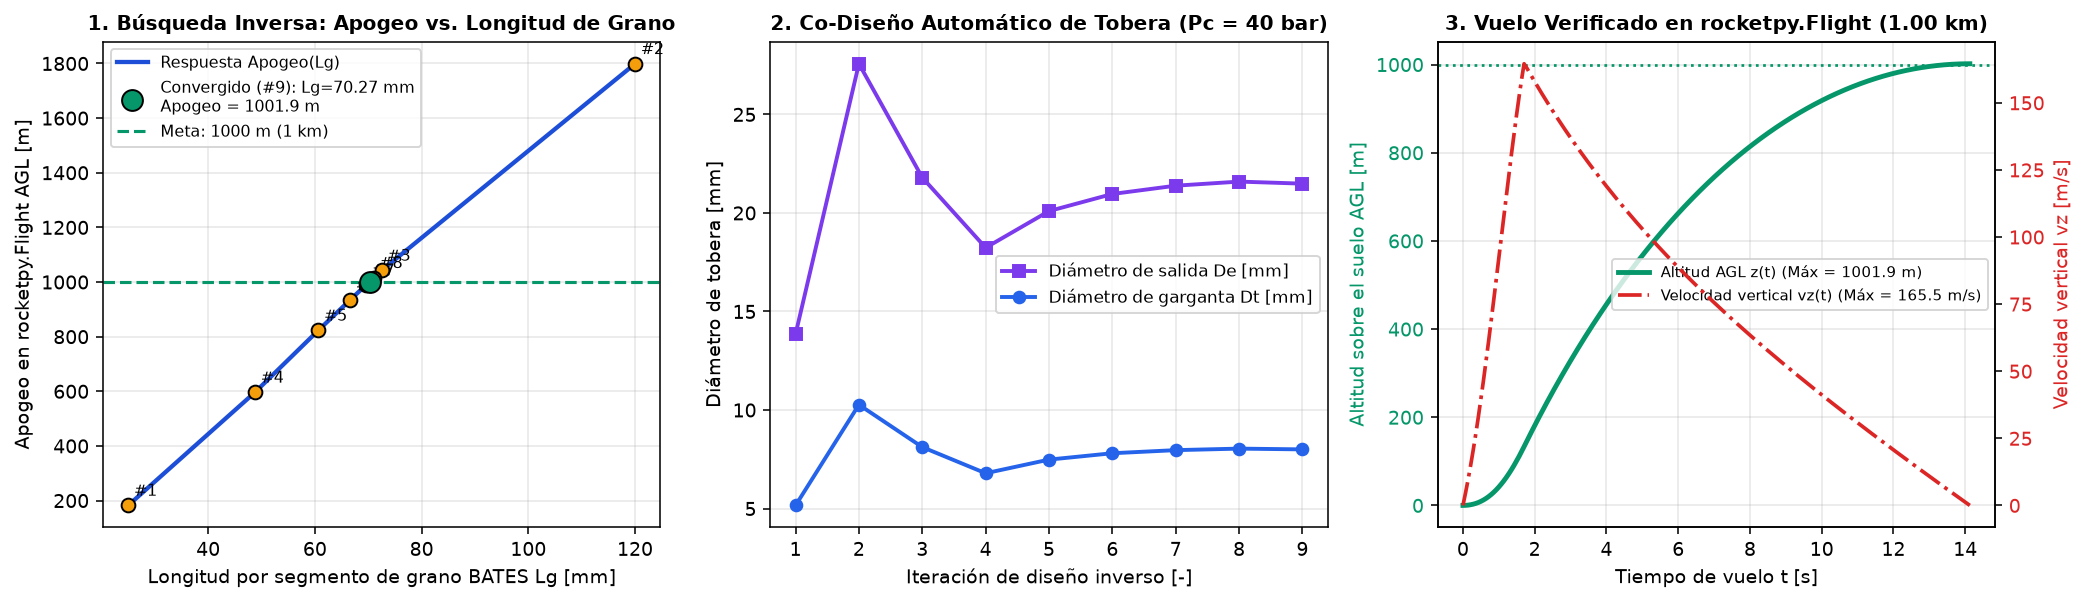

In [4]:
def plot_1km_mission_convergence(design_res, save_path: Path | None = None):
    """Grafica el proceso de convergencia hacia 1 km de apogeo y la trayectoria de RocketPy Flight."""
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.4), dpi=140)

    # Ordenar puntos evaluados por longitud de grano para trazar la curva suave
    recs_sorted = sorted(design_res.history, key=lambda r: r.grain_length_m)
    lg_sorted = [r.grain_length_m * 1e3 for r in recs_sorted]
    ap_sorted = [r.simulated_apogee_m for r in recs_sorted]

    # Panel 1: Apogeo vs Longitud de grano Lg
    ax1 = axs[0]
    ax1.plot(
        lg_sorted,
        ap_sorted,
        color="#1d4ed8",
        lw=2.2,
        ls="-",
        label="Respuesta Apogeo(Lg)",
    )
    for r in design_res.history[:-1]:
        ax1.scatter(
            r.grain_length_m * 1e3,
            r.simulated_apogee_m,
            color="#f59e0b",
            s=50,
            zorder=5,
            edgecolor="black",
        )
        ax1.annotate(
            f"#{r.iteration}",
            (r.grain_length_m * 1e3, r.simulated_apogee_m),
            xytext=(3, 5),
            textcoords="offset points",
            fontsize=8,
        )

    last = design_res.history[-1]
    ax1.scatter(
        [last.grain_length_m * 1e3],
        [last.simulated_apogee_m],
        color="#059669",
        s=115,
        zorder=6,
        edgecolor="black",
        label=f"Convergido (#{last.iteration}): Lg={last.grain_length_m * 1e3:.2f} mm\nApogeo = {last.simulated_apogee_m:.1f} m",
    )
    ax1.axhline(1000.0, color="#059669", ls="--", lw=1.6, label="Meta: 1000 m (1 km)")
    ax1.set_title(
        "1. Búsqueda Inversa: Apogeo vs. Longitud de Grano",
        fontsize=10.5,
        fontweight="bold",
    )
    ax1.set_xlabel("Longitud por segmento de grano BATES Lg [mm]")
    ax1.set_ylabel("Apogeo en rocketpy.Flight AGL [m]")
    ax1.grid(True, alpha=0.3)
    ax1.legend(loc="upper left", fontsize=8.0)

    # Panel 2: Co-dimensionamiento automático de Garganta Dt y Salida De vs Iteración
    ax2 = axs[1]
    iters = [r.iteration for r in design_res.history]
    dt_hist = [r.throat_diameter_m * 1e3 for r in design_res.history]
    de_hist = [r.exit_diameter_m * 1e3 for r in design_res.history]
    ax2.plot(
        iters,
        de_hist,
        marker="s",
        color="#7c3aed",
        lw=2.0,
        label="Diámetro de salida De [mm]",
    )
    ax2.plot(
        iters,
        dt_hist,
        marker="o",
        color="#2563eb",
        lw=2.0,
        label="Diámetro de garganta Dt [mm]",
    )
    ax2.set_title(
        "2. Co-Diseño Automático de Tobera (Pc = 40 bar)",
        fontsize=10.5,
        fontweight="bold",
    )
    ax2.set_xlabel("Iteración de diseño inverso [-]")
    ax2.set_ylabel("Diámetro de tobera [mm]")
    ax2.set_xticks(iters)
    ax2.grid(True, alpha=0.3)
    ax2.legend(loc="center right", fontsize=8.5)

    # Panel 3: Trayectoria real z(t) y velocidad vz(t) en rocketpy.Flight hasta 1 km
    ax3 = axs[2]
    fl = design_res.flight
    t_arr = np.linspace(0.0, float(fl.apogee_time), 200)
    z_agl = np.array([float(fl.z(t)) - float(env.elevation) for t in t_arr])
    vz_arr = np.array([float(fl.vz(t)) for t in t_arr])

    ln1 = ax3.plot(
        t_arr,
        z_agl,
        color="#059669",
        lw=2.5,
        label=f"Altitud AGL z(t) (Máx = {design_res.simulated_apogee_m:.1f} m)",
    )
    ax3.axhline(1000.0, color="#059669", ls=":", lw=1.4)
    ax3.set_xlabel("Tiempo de vuelo t [s]")
    ax3.set_ylabel("Altitud sobre el suelo AGL [m]", color="#059669")
    ax3.tick_params(axis="y", labelcolor="#059669")
    ax3.grid(True, alpha=0.3)

    ax3_v = ax3.twinx()
    ln2 = ax3_v.plot(
        t_arr,
        vz_arr,
        color="#dc2626",
        lw=1.9,
        ls="-.",
        label=f"Velocidad vertical vz(t) (Máx = {float(fl.max_speed):.1f} m/s)",
    )
    ax3_v.set_ylabel("Velocidad vertical vz [m/s]", color="#dc2626")
    ax3_v.tick_params(axis="y", labelcolor="#dc2626")

    lns = ln1 + ln2
    ax3.legend(lns, [ln.get_label() for ln in lns], loc="center right", fontsize=7.8)
    ax3.set_title(
        "3. Vuelo Verificado en rocketpy.Flight (1.00 km)",
        fontsize=10.5,
        fontweight="bold",
    )

    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_1km_mission_convergence(design, fig_dir / "06_srad38_bisection_convergence.png")

---
## 3. ¿Cómo Calcula PropulPy la Tobera Requerida? (`dimension_nozzle` y Presión de Salida de Gas)

Dentro del bucle automático anterior, una vez conocido el diámetro de garganta $D_t = 7.45\text{ mm}$ y la presión nominal de cámara $P_c = 40\text{ bar}$, `PropulPy` llamó a **`dimension_nozzle()`**.

### ¿Cómo funciona `dimension_nozzle()`?
Dada la información de la garganta ($D_t$), la presión de cámara ($P_c$), el diámetro de cámara ($D_c$) y el **nivel de presión saliente de gas que requerimos a la salida de la tobera ($P_e$)**, la función invierte las ecuaciones isentrópicas 1D:
1. Calcula el **número de Mach supersónico de salida $M_e$** necesario para expandir el gas desde $P_c$ hasta la presión de salida requerida $P_e$:
   $$M_e = \sqrt{\frac{2}{\gamma - 1}\left[\left(\frac{P_c}{P_e}\right)^{\frac{\gamma - 1}{\gamma}} - 1\right]}$$
2. Determina la **razón de expansión geométrica $\varepsilon = A_e / A_t$** y por tanto el **diámetro exacto de salida $D_e = D_t\sqrt{\varepsilon}$**.
3. Calcula las longitudes axiales de mecanizado del cono convergente ($L_{\text{conv}}$), garganta ($L_t$) y cono divergente ($L_{\text{div}}$).

Veamos el reporte y el **plano visual generado por `design.nozzle_dims.plot()`**:

                 CONICAL NOZZLE DIMENSION REPORT
MACHINING GEOMETRY (mm):
  * Throat Diameter (Dt)     : 8.00 mm
  * Exit Diameter (De)       : 21.49 mm
  * Convergent Length (Lconv): 29.44 mm  (half-angle = 30.0°)
  * Throat Land Length (Lt)  : 1.60 mm
  * Divergent Length (Ldiv)  : 25.16 mm  (half-angle = 15.0°)
  * Total Nozzle Length      : 56.21 mm
-----------------------------------------------------------------
GAS DYNAMICS & DELIVERED PERFORMANCE:
  * Expansion Ratio (eps)    : 7.21
  * Exit Mach Number (Me)    : 2.903
  * Exit Static Pressure (Pe): 0.909 bar (90863 Pa)
  * Delivered Cf             : 1.415
  * Delivered Thrust         : 284.7 N


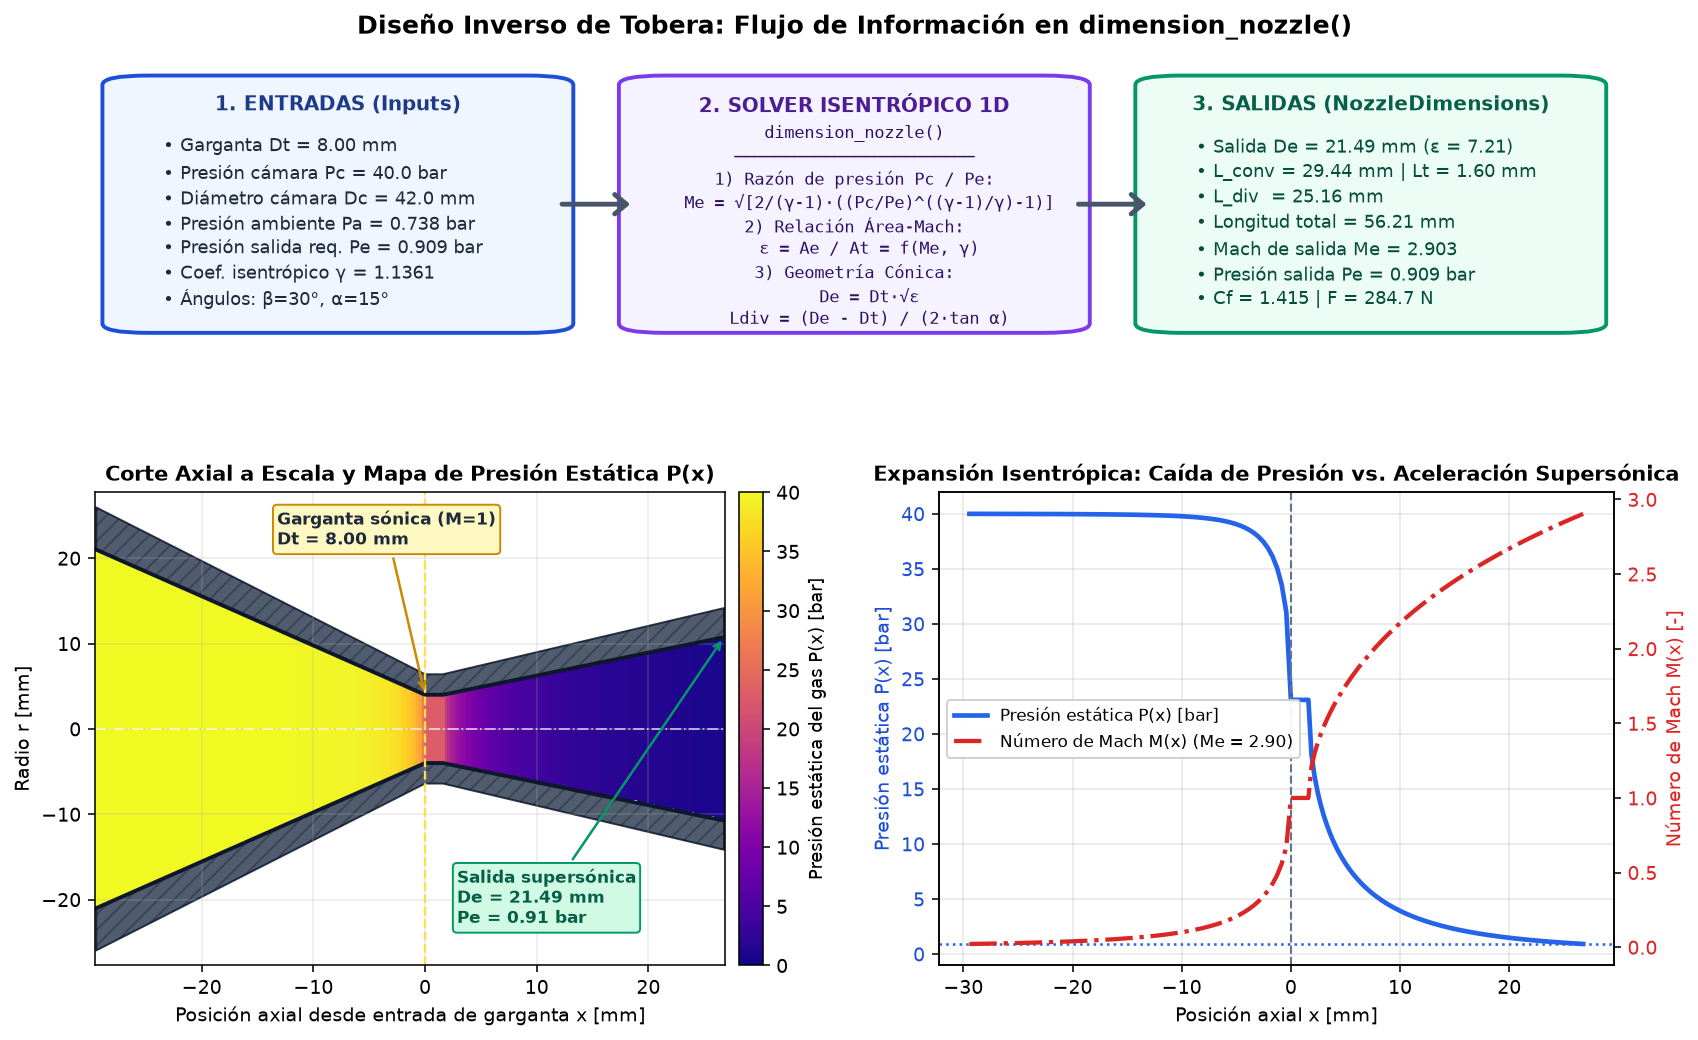

In [5]:
# Reporte de cotas de mecanizado de la tobera del motor de 1 km
design.nozzle_dims.report()

# Plano visual de 3 paneles: Entradas -> Solver Isentrópico -> Salidas y Mapa 2D de Presión P(x)
_ = design.nozzle_dims.plot(save_path=fig_dir / "02_dimension_nozzle_blueprint.png")

### 3.1 ¿Qué ocurre si exigimos distintas Presiones Salientes de Gas (`target_exit_pressure`)?

Si deseas que el gas salga de la tobera a un **nivel exacto de presión estática $P_e$** elegido por ti, basta con pasar `target_exit_pressure=Pe` a `dimension_nozzle()`. En la siguiente infografía generada por código mostramos cómo `dimension_nozzle()` modifica el diámetro de salida $D_e$ y la longitud divergente $L_{\text{div}}$ en función de la presión saliente requerida $P_e$, ilustrando los tres regímenes físicos de la pluma supersónica:

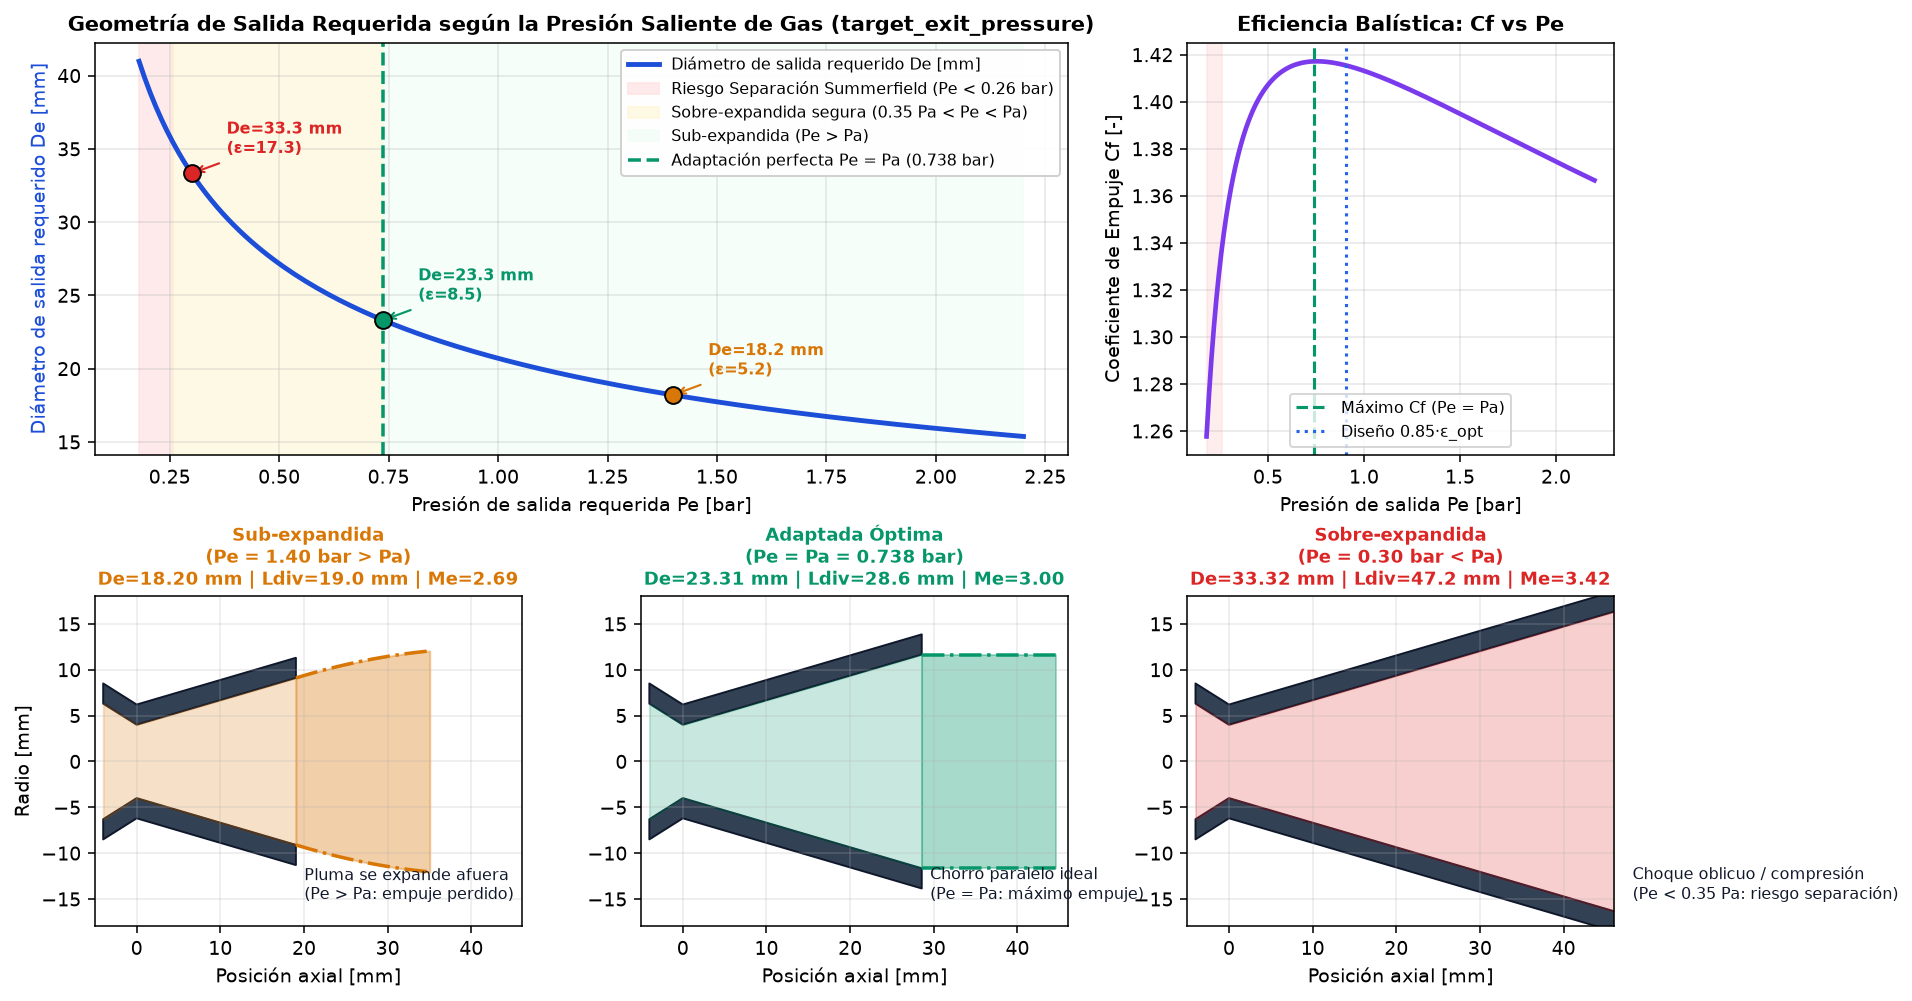

In [6]:
def plot_exit_pressure_parametric_study(save_path: Path | None = None):
    """Ilustra cómo dimension_nozzle ajusta la tobera según la presión de salida Pe requerida."""
    pc = 40.0e5
    dt = design.nozzle_dims.throat_diameter
    pa = amb.ground_pressure
    p_sep = 0.35 * pa  # Criterio de separación de Summerfield

    pe_targets = np.linspace(0.18e5, 2.20e5, 160)
    de_mm_list, cf_list = [], []

    for pe_req in pe_targets:
        nd = dimension_nozzle(
            throat_diameter=dt,
            chamber_pressure=pc,
            propellant=prop,
            chamber_diameter=42.0e-3,
            target_exit_pressure=float(pe_req),
            ambient_pressure=pa,
            efficiency=0.90,
        )
        de_mm_list.append(nd.exit_diameter * 1e3)
        cf_list.append(nd.thrust_coefficient)

    pe_bar = pe_targets / 1e5
    pa_bar = pa / 1e5
    p_sep_bar = p_sep / 1e5

    cases = [
        ("Sub-expandida\n(Pe = 1.40 bar > Pa)", 1.40e5, "#d97706"),
        ("Adaptada Óptima\n(Pe = Pa = 0.738 bar)", pa, "#059669"),
        ("Sobre-expandida\n(Pe = 0.30 bar < Pa)", 0.30e5, "#dc2626"),
    ]

    fig = plt.figure(figsize=(14, 8.2), dpi=140)
    gs = fig.add_gridspec(2, 3, height_ratios=[1.25, 1.0], hspace=0.38, wspace=0.28)

    ax1 = fig.add_subplot(gs[0, :2])
    ax1.plot(
        pe_bar,
        de_mm_list,
        color="#1d4ed8",
        lw=2.5,
        label="Diámetro de salida requerido De [mm]",
    )
    ax1.axvspan(
        pe_bar[0],
        p_sep_bar,
        color="#fee2e2",
        alpha=0.7,
        label=f"Riesgo Separación Summerfield (Pe < {p_sep_bar:.2f} bar)",
    )
    ax1.axvspan(
        p_sep_bar,
        pa_bar,
        color="#fef3c7",
        alpha=0.45,
        label="Sobre-expandida segura (0.35 Pa < Pe < Pa)",
    )
    ax1.axvspan(
        pa_bar, pe_bar[-1], color="#ecfdf5", alpha=0.45, label="Sub-expandida (Pe > Pa)"
    )
    ax1.axvline(
        pa_bar,
        color="#059669",
        ls="--",
        lw=1.8,
        label=f"Adaptación perfecta Pe = Pa ({pa_bar:.3f} bar)",
    )

    for _label_c, pe_val, col in cases:
        nd_c = dimension_nozzle(
            dt, pc, prop, 42.0e-3, target_exit_pressure=pe_val, ambient_pressure=pa
        )
        ax1.scatter(
            [pe_val / 1e5],
            [nd_c.exit_diameter * 1e3],
            color=col,
            s=75,
            zorder=5,
            edgecolor="black",
        )
        ax1.annotate(
            f"De={nd_c.exit_diameter * 1e3:.1f} mm\n(ε={nd_c.area_ratio:.1f})",
            xy=(pe_val / 1e5, nd_c.exit_diameter * 1e3),
            xytext=(pe_val / 1e5 + 0.08, nd_c.exit_diameter * 1e3 + 1.4),
            fontsize=8.3,
            fontweight="bold",
            color=col,
            arrowprops={"arrowstyle": "->", "color": col, "lw": 1.1},
        )

    ax1.set_title(
        "Geometría de Salida Requerida según la Presión Saliente de Gas (target_exit_pressure)",
        fontsize=11,
        fontweight="bold",
    )
    ax1.set_xlabel("Presión de salida requerida Pe [bar]")
    ax1.set_ylabel("Diámetro de salida requerido De [mm]", color="#1d4ed8")
    ax1.grid(True, alpha=0.3)
    ax1.legend(loc="upper right", fontsize=8.0, framealpha=0.92)

    ax2 = fig.add_subplot(gs[0, 2])
    ax2.plot(pe_bar, cf_list, color="#7c3aed", lw=2.4)
    ax2.axvline(pa_bar, color="#059669", ls="--", lw=1.6, label="Máximo Cf (Pe = Pa)")
    ax2.axvline(
        design.nozzle_dims.exit_pressure / 1e5,
        color="#2563eb",
        ls=":",
        lw=1.6,
        label="Diseño 0.85·ε_opt",
    )
    ax2.axvspan(pe_bar[0], p_sep_bar, color="#fee2e2", alpha=0.6)
    ax2.set_title("Eficiencia Balística: Cf vs Pe", fontsize=11, fontweight="bold")
    ax2.set_xlabel("Presión de salida Pe [bar]")
    ax2.set_ylabel("Coeficiente de Empuje Cf [-]")
    ax2.grid(True, alpha=0.3)
    ax2.legend(loc="lower center", fontsize=8.2)

    for idx, (title_c, pe_val, col) in enumerate(cases):
        ax_c = fig.add_subplot(gs[1, idx])
        nd_c = dimension_nozzle(
            dt, pc, prop, 42.0e-3, target_exit_pressure=pe_val, ambient_pressure=pa
        )
        rt = nd_c.throat_diameter * 1e3 / 2.0
        re = nd_c.exit_diameter * 1e3 / 2.0
        ldiv = nd_c.divergent_length * 1e3

        x_noz = np.array([-4.0, 0.0, ldiv])
        r_noz = np.array([rt + 2.3, rt, re])
        ax_c.fill_between(
            x_noz, r_noz, r_noz + 2.2, color="#334155", edgecolor="#0f172a", hatch="///"
        )
        ax_c.fill_between(
            x_noz,
            -r_noz - 2.2,
            -r_noz,
            color="#334155",
            edgecolor="#0f172a",
            hatch="///",
        )
        ax_c.fill_between(x_noz, -r_noz, r_noz, color=col, alpha=0.22)

        x_plume = np.linspace(ldiv, ldiv + 16.0, 60)
        dx_p = x_plume - ldiv
        if pe_val > pa * 1.05:
            r_plume = re + 0.28 * dx_p - 0.006 * dx_p**2
            plume_note = "Pluma se expande afuera\n(Pe > Pa: empuje perdido)"
        elif abs(pe_val - pa) <= 0.05 * pa:
            r_plume = np.full_like(x_plume, re)
            plume_note = "Chorro paralelo ideal\n(Pe = Pa: máximo empuje)"
        else:
            r_plume = re - 0.22 * dx_p + 0.011 * dx_p**2
            plume_note = (
                "Choque oblicuo / compresión\n(Pe < 0.35 Pa: riesgo separación)"
            )
            ax_c.plot(
                [ldiv, ldiv + 8.0, ldiv],
                [re, 0.0, -re],
                color="#dc2626",
                ls="--",
                lw=1.5,
            )

        ax_c.fill_between(x_plume, -r_plume, r_plume, color=col, alpha=0.35)
        ax_c.plot(x_plume, r_plume, color=col, lw=1.8, ls="-.")
        ax_c.plot(x_plume, -r_plume, color=col, lw=1.8, ls="-.")
        ax_c.set_xlim(-5, 46)
        ax_c.set_ylim(-18, 18)
        ax_c.set_title(
            f"{title_c}\nDe={nd_c.exit_diameter * 1e3:.2f} mm | Ldiv={ldiv:.1f} mm | Me={nd_c.exit_mach:.2f}",
            fontsize=9.3,
            fontweight="bold",
            color=col,
        )
        ax_c.text(ldiv + 1.0, -15.0, plume_note, fontsize=8.0, color="#0f172a")
        ax_c.set_xlabel("Posición axial [mm]")
        if idx == 0:
            ax_c.set_ylabel("Radio [mm]")
        ax_c.grid(True, alpha=0.25)

    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_exit_pressure_parametric_study(fig_dir / "03_nozzle_exit_pressure_regimes.png")

---
## 4. Geometrías de Grano Soportadas (`BATES`, `Finocyl`, `Star`, `EndBurner`)

Además de los granos `BATES` empleados en nuestro motor de $1\text{ km}$, `PropulPy` permite modelar granos 2D perforados (`Finocyl`, `Star`) mediante la **Transformada de Distancia Euclidiana (`scipy.ndimage.distance_transform_edt`)**, igual que `openMotor`:

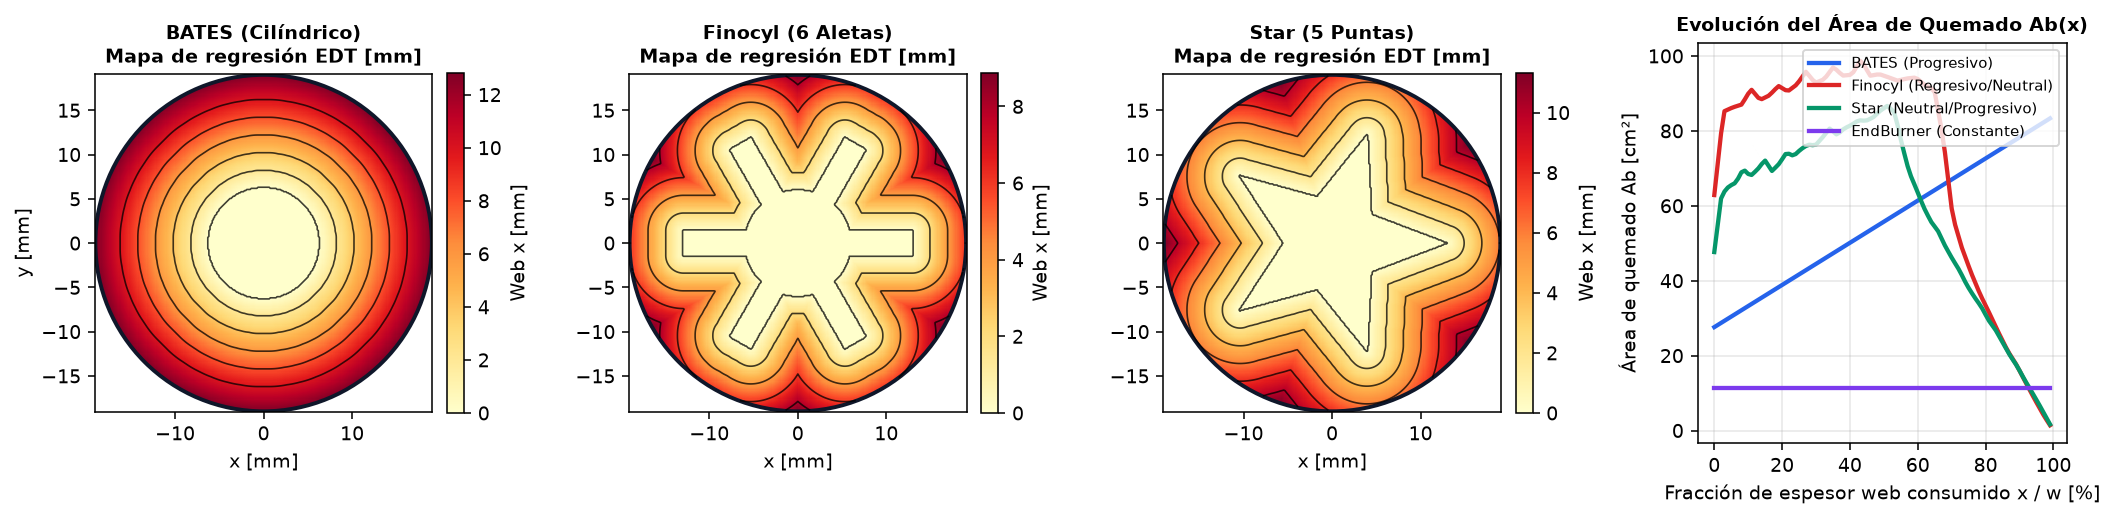

In [7]:
def plot_grain_geometries_edt(save_path: Path | None = None):
    """Visualiza los mapas de regresión 2D (EDT) de BATES, Finocyl y Star y sus curvas Ab(x)."""
    d_out = 0.038
    length = design.grain_length

    g_bates = BATES(
        diameter=d_out, core_diameter=0.0125, length=length, inhibited_ends="both"
    )
    g_fino = Finocyl(
        diameter=d_out,
        core_diameter=0.012,
        fin_length=0.007,
        fin_width=0.0028,
        num_fins=6,
        length=length,
        inhibited_ends="both",
    )
    g_star = Star(
        diameter=d_out,
        inner_diameter=0.011,
        point_diameter=0.026,
        num_points=5,
        length=length,
        inhibited_ends="both",
    )
    g_end = EndBurner(diameter=d_out, length=0.015)

    fig, axs = plt.subplots(1, 4, figsize=(15, 3.8), dpi=140)
    r_out = d_out / 2.0
    lin = np.linspace(-r_out, r_out, 301)
    dx = lin[1] - lin[0]
    X, Y = np.meshgrid(lin, lin)
    R = np.hypot(X, Y)
    inside_casing = R <= r_out

    grain_2d_specs = [
        ("BATES (Cilíndrico)", R <= (0.0125 / 2.0)),
        ("Finocyl (6 Aletas)", g_fino._build_core_mask(X, Y)),
        ("Star (5 Puntas)", g_star._build_core_mask(X, Y)),
    ]

    for idx, (title, core_mask) in enumerate(grain_2d_specs):
        ax = axs[idx]
        dist_mm = distance_transform_edt(~(core_mask & inside_casing)) * dx * 1e3
        dist_mm[~inside_casing] = np.nan
        dist_mm[core_mask & inside_casing] = 0.0

        im = ax.pcolormesh(X * 1e3, Y * 1e3, dist_mm, cmap="YlOrRd", shading="auto")
        ax.contour(
            X * 1e3,
            Y * 1e3,
            dist_mm,
            levels=[0.1, 2.0, 4.0, 6.0, 8.0, 10.0],
            colors="black",
            linewidths=0.85,
            alpha=0.75,
        )
        circle = plt.Circle((0, 0), r_out * 1e3, fill=False, ec="#0f172a", lw=2.0)
        ax.add_patch(circle)
        ax.set_aspect("equal")
        ax.set_title(
            f"{title}\nMapa de regresión EDT [mm]", fontsize=10, fontweight="bold"
        )
        ax.set_xlabel("x [mm]")
        if idx == 0:
            ax.set_ylabel("y [mm]")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Web x [mm]")

    ax_ab = axs[3]
    for label, g, col in [
        ("BATES (Progresivo)", g_bates, "#2563eb"),
        ("Finocyl (Regresivo/Neutral)", g_fino, "#dc2626"),
        ("Star (Neutral/Progresivo)", g_star, "#059669"),
        ("EndBurner (Constante)", g_end, "#7c3aed"),
    ]:
        xs = np.linspace(0.0, g.web_thickness * 0.99, 100)
        ab_cm2 = np.asarray(g.burn_area(xs)) * 1e4
        ax_ab.plot(xs / g.web_thickness * 100.0, ab_cm2, lw=2.2, color=col, label=label)

    ax_ab.set_title(
        "Evolución del Área de Quemado Ab(x)", fontsize=10, fontweight="bold"
    )
    ax_ab.set_xlabel("Fracción de espesor web consumido x / w [%]")
    ax_ab.set_ylabel("Área de quemado Ab [cm²]")
    ax_ab.grid(True, alpha=0.3)
    ax_ab.legend(fontsize=7.8, loc="upper right")

    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_grain_geometries_edt(fig_dir / "04_grain_edt_geometries.png")

---
## 5. Auditoría de Seguridad, Curvas de Balística Interna y Verificación Explícita en `rocketpy.Flight`

Finalmente, auditamos el motor convergente (`design.motor`), visualizamos sus 4 curvas de balística interna (`design.ballistics_results.plot()`), exportamos los archivos `.eng` / `.ric` / `.csv`, y **hacemos la prueba final explícita en `RocketPy`**:
1. Convertimos `design.ballistics_results.to_rocketpy(...)` en un objeto `rocketpy.SolidMotor`.
2. Lo agregamos a nuestro objeto `rocket` (`rocket.add_motor(rp_motor, position=-1.10)`).
3. Ejecutamos `flight = Flight(rocket=rocket, environment=env, ...)` y comprobamos el apogeo alcanzado.

                  PROPULPY MOTOR DESIGN & SAFETY AUDIT
[OK]       Port-to-Throat Ratio (Ap/At)    : Port-to-throat ratio (2.44) is safe (>= 2.0).
[OK]       Initial Kn                      : Initial Kn (285.3) is within nominal operating range (200 - 350).
[OK]       Peak Kn                         : Peak Kn (349.3) is within nominal operating range (<= 350).
[OK]       Grain Core Ratio (d/D)          : Grain core-to-diameter ratio d/D (0.33) is well proportioned (0.25 - 0.60).
[OK]       Grain Aspect Ratio (L/D)        : Grain segment aspect ratio L/D (1.85) promotes near-neutral burn (1.2 - 2.5).
[OK]       Peak Chamber Pressure (bar)     : Peak chamber pressure (40.9 bar) is within normal sugar/composite bounds.
[OK]       Casing Safety Factor            : Casing safety factor (5.87) is generous (>= 2.0).
[OK]       Nozzle Separation (Pe/Pa)       : Nozzle exit pressure ratio Pe/Pa (0.60) is well above separation threshold.
             PROPULPY SOLID MOTOR SUMMARY (I254)
Propellant

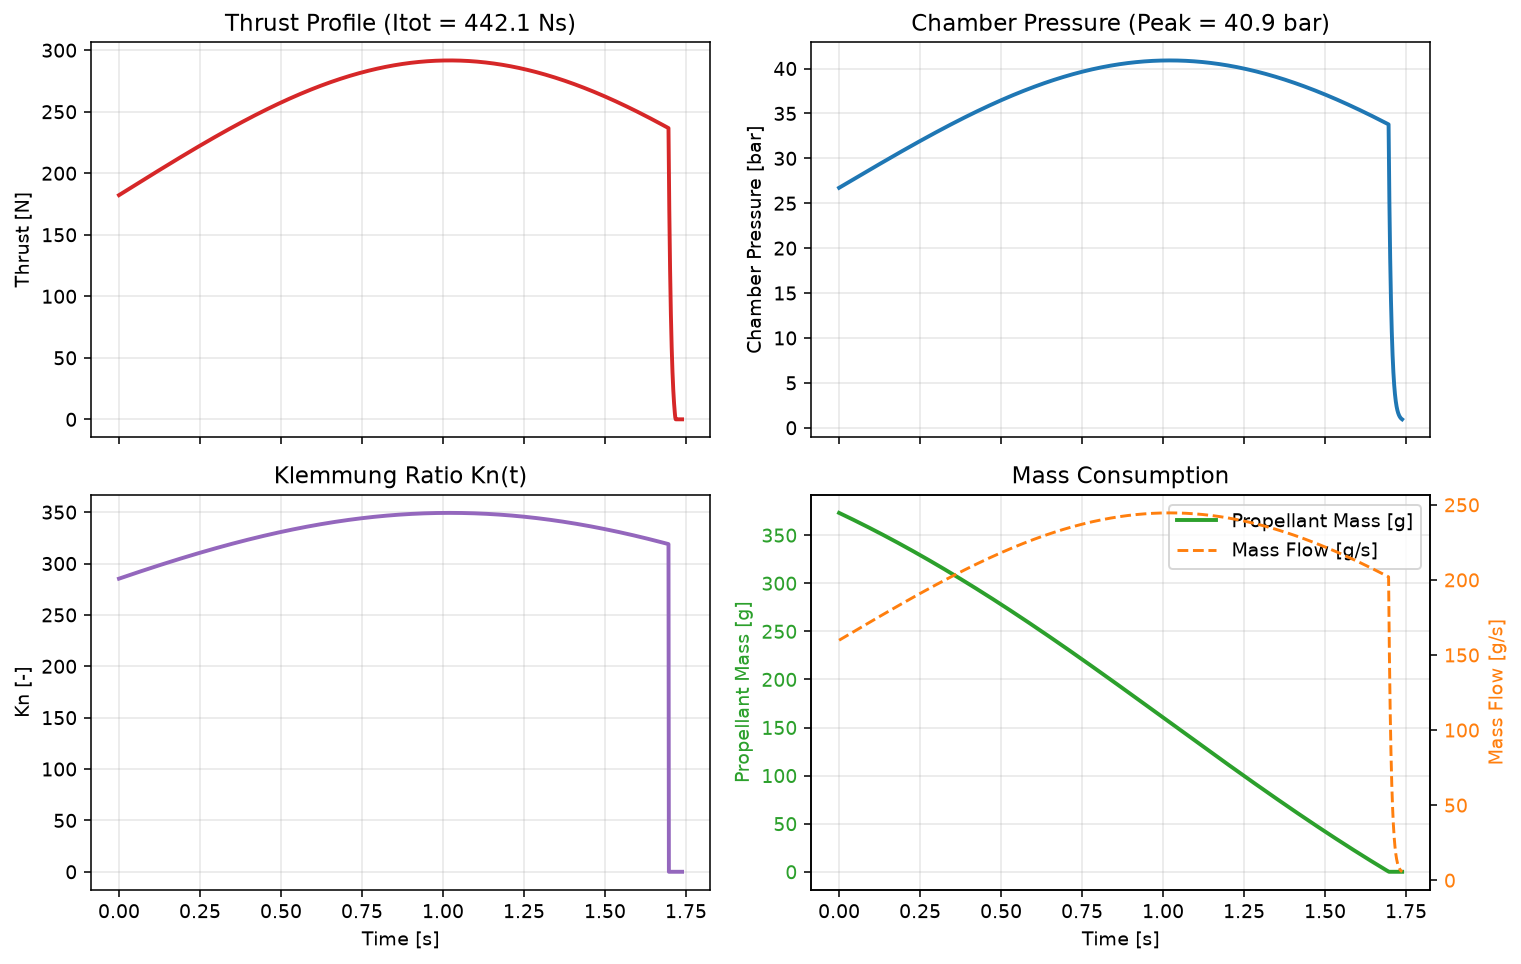

In [8]:
# 1. Auditoría de seguridad y resumen balístico del motor diseñado para 1 km
print_check_report(design.motor)
results = design.ballistics_results
results.info()

# 2. Dashboard de 4 paneles de balística interna
fig_sim = results.plot(show=False)
fig_sim.savefig(
    fig_dir / "05_ultraluminics_firing_dashboard.png", dpi=150, bbox_inches="tight"
)
plt.show()

# 3. Exportar a CSV, RASP (.eng) y openMotor (.ric)
out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)
results.export_csv(out_dir / "ultraluminics_1km_motor.csv")
results.export_eng(out_dir / "ultraluminics_1km_motor.eng", motor_name="I240-UL")
ric_path = results.export_ric(
    out_dir / "ultraluminics_1km_motor.ric", description="UltraLuminics 1km KNSB"
)

# 4. Prueba explícita: crear el objeto SolidMotor de RocketPy, montarlo en nuestro Rocket y correr Flight
rp_motor = results.to_rocketpy(
    dry_mass=0.500,
    dry_inertia=(0.04, 0.04, 0.001),
    center_of_dry_mass_position=0.12,
)
rocket.add_motor(rp_motor, position=-1.10)

flight = Flight(
    rocket=rocket,
    environment=env,
    rail_length=3.0,
    inclination=85.0,
    heading=0.0,
    max_time_step=max(float(results.burn_time) / 50.0, 1e-4),
    terminate_on_apogee=True,
)

apogee_agl_m = float(flight.apogee - env.elevation)
print("\n==========================================================================")
print("          VERIFICACIÓN FINAL EN ROCKETPY (SolidMotor + Flight)            ")
print("==========================================================================")
print(f"  * Impulso total en rocketpy.SolidMotor : {rp_motor.total_impulse:.1f} N·s")
print(f"  * Altitud de lanzamiento (Bogotá)      : {float(env.elevation):.1f} m MSNM")
print(f"  * Apogeo absoluto MSNM                 : {float(flight.apogee):.2f} m MSNM")
print(
    f"  * Apogeo sobre el suelo (AGL)          : {apogee_agl_m:.2f} m  (Objetivo: 1000.00 m)"
)
print(f"  * Velocidad máxima alcanzada           : {float(flight.max_speed):.2f} m/s")
print(
    f"  * Velocidad a la salida del riel       : {float(flight.out_of_rail_velocity):.2f} m/s"
)
print("==========================================================================")